# DQN Modèle

Ce notebook sert à l'initialisation et à l'entrainement du modèle DQN à l'atterrissage du modèle lunaire.
Le Deep Q-Network (DQN) est un algorithme d'apprentissage par renforcement (Deep Reinforcement Learning). Il combine le Q-learning traditionnel avec les réseaux de neurones profonds. En effet, en Q-learning classique, les valeurs de Q(s, a) (c'est la qualité de a dans un état s), sont stoké dans une Q-Table. Cette table permet de stocké tous les états possible du système. Cependant, ici, avec notre modèle lunaire et ses 8 paramètres, le nombre d'état est techniquement infini (largement trop grand pour être stocké dans une table). Le DQN va donc transformer cette table en réseau de neurones. Le but de se réseau est d'estimer les valeurs Q.

## Import
Nous importons dans cette section toute les librairie qui nous serons utiles pour effectuer l'entrainement ou la justification des résultats

In [1]:
import gymnasium as gym                     # gymnasium : Bibliothèque Python open-source utilisée pour développer et tester des algorithmes d'apprentissage par renforcement.
import csv                                  # csv : Permet de sauvegarder les résultats des entrainements dans un CSV afin de les réutiliser pour des graphiques par exemples.
from pathlib import Path                    # pathlib : Permet d'aller chercher un fichier pour le modifier, écrire dedans et donc sauvergarder les résultats des entrainements.
import matplotlib.pyplot as plt             # matplotlib : Permet de créer et tracer des graphiques afin d'afficher et de justifier visuellement les résultats, voir l'évolutions des données et comprendre le fonctionnement de nos modèles.
import torch                                # torch : Bibliothèque logicielle open source utilisée pour développer et entraîner des modèles d'intelligence artificielle et de deep learning.
import torch.nn as nn                       # nn : Sert à entraîner des intelligences artificielles dans notre cas, prédire des données en imitant le fonctionnement du cerveau humain.
from collections import deque               # deque : Sert à stocker une liste d'éléments en permettant d'ajouter ou de supprimer des objets très rapidement des deux côtés.
import random                               # random : Permet de choisir des élements aléatoire comme pour l'Epsilon-Greedy, le Replay Buffer ou encore la seed d'entrainement.
import torch.optim as optim                 # optim : Module de PyTorch qui regroupe tous les algorithmes d'optimisation (comme le "adam" que nous utilisons).
import numpy as np                          # numpy : Permet d'effectuer des tableaux de valeurs avec des dimensions très élevées.

In [2]:
env = gym.make("LunarLander-v3")

### Raison de fin
Afin de voir de quelle manière les 100 essais aléatoire se terminent, nous créons une fonction qui renvoie la manière dont l'essai c'est terminé. Cela nous permet de savoir combien de fois le module c'est cracher, est sorti de l'écran ou bien à mis trop de temps à se terminer.

In [3]:
def end_reason(truncated, next_state, reward):
    if truncated:
        return "truncated"
    if abs(next_state[0]) >= 1.0:
        return "out_of_viewport"
    if reward == 100:
        return "at_rest"
    return "crash"

### Création de l'environnement PyTorch
L'environnement PyTorch va être l'endroit ou le modèle va être entrainé. Il permet de créer un réseau de neurone, qui va être utilisé par le modèle pour effectué ses entrainements.

In [4]:
class DQN(nn.Module):
    def __init__(self, state_size=env.observation_space.shape[0], action_size=env.action_space.n):
        super(DQN, self).__init__()

        self.network = nn.Sequential(
            nn.Linear(state_size, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, action_size)
        )

    def forward(self, state):
        return self.network(state)

### Epsilon-greedy

Epsilon-greedy est la fonction qui donne au modèle sa façon d'apprendre. On vient modifier l'hyperparamètre Epsilon ε, il oscillent entre 0 et 1. C'est la probabilité avec laquelle il va effectué une action aléatoirement ou une action grâce à son entrainement. Plus ε est élevé, plus ils à de chances de faire une action aléatoire. Au départ, on met ε à 1 car ils n'a pas encore d'expériences en mémoire. Il n'a donc pas encore besoin de passé par de l'exploitation, il reste donc en exploration. A chaque étape, on va venir diminuer tout doucement l'epsilon afin que petit à petit, il ne fasse des choix que via ses expériences passées. 

In [5]:
def select_action(state, model, epsilon, action_size=env.action_space.n):
    # Exploration : choisir une action au hasard
    if random.random() < epsilon:
        return random.randrange(action_size)

    # Exploitation : choisir la meilleure action selon le réseau
    with torch.no_grad():
        state = torch.tensor(state, dtype=torch.float32)
        q_values = model(state)

    return torch.argmax(q_values).item()

### ReplayBuffer
Et justement, Replay Buffer permet de gérer cette mémoire d'expérience passé. Replay Buffer à une capacité maximum de stockage, qui quand elle est dépassée, enlève les plus anciennes données pour les remplacer par les nouvelles. Lorsque, grâce à l'Epsilon, le choix de la prochaine action doit être faite via les anciennes expériences. Nous allons utiliser la méthode "sample", qui va récupérer un nombre n d'expériences aléatoirement, afin de ne pas donner aux modèles des expériences qui soient trop proches ou trop éloignées de son état actuel.

In [6]:
class ReplayBuffer:

  def __init__(self, capacity):
    self.buffer = deque(maxlen=capacity)

  def __len__(self):
    return len(self.buffer)

  def add(self, experience):
    self.buffer.append(experience)

  def sample(self, batch_size):
    return random.sample(self.buffer, batch_size)

### Train Step
Ici, c'est l'étape d'apprentissage de notre agent DQN. Elle sélectionne aléatoirement un lot d'expériences dans le Replay Buffer, calcule les valeurs Q prédites et les valeurs cibles, mesure l'erreur avec la fonction MSE, puis met à jour les paramètres du réseau principal grâce à la rétropropagation et à l'optimiseur.

In [7]:
BATCH_SIZE = 50
GAMMA = 0.999

def train_step(model, buffer, target_model, loss_fn, optimizer):

    # On attend d'avoir assez d'expériences pour former un lot
    if len(buffer) < BATCH_SIZE:
        return None

    # On va venir récupérer le nombre d'expériences de manière aléatoire
    batch = buffer.sample(BATCH_SIZE)

    # On va ensuite séparer les expériences via les paramètres (le zip permet de régrouper tous les élémets de "batch" en un point)
    states, actions, rewards, next_states, terminated, truncated = zip(*batch)

    # Puis on va convertir ces paramètres en tenseurs PyTorch (utilisable par le modèle)
    states = torch.as_tensor(np.asarray(states), dtype=torch.float32)
    actions = torch.tensor(actions, dtype=torch.int64).unsqueeze(1)
    rewards = torch.tensor(rewards, dtype=torch.float32)
    next_states = torch.as_tensor(np.asarray(next_states), dtype=torch.float32)
    terminated = torch.tensor(terminated, dtype=torch.float32)

    # 4. Prédictions du réseau principal pour les actions effectuées
    current_q_values = model(states).gather(1, actions).squeeze(1)

    # On calcule les valeurs cibles avec le réseau cible
    with torch.no_grad():
        next_q_values = target_model(next_states)
        max_next_q_values = next_q_values.max(dim=1).values
        target_q_values = (rewards + GAMMA * (1 - terminated) * max_next_q_values)

    # Et on calcule la fonction de perte MSE
    loss = loss_fn(current_q_values, target_q_values)

    # Mise à jour des paramètres du réseau principal
    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

    # Et enfin, on renvoie la valeur de la perte pour pouvoir la suivre
    return loss.item()

### Entrainement du modèle
C'est la boucle d'entrainement du modèle DQN. On assemble tous les éléments que l'on a initialisés avant, dans cette partie.
On va tester avec 1150 épisodes. 
On met bien le Epsilon à 1 au début et à chaque épisode je le multiplie par EPSILON_DECAY.
On fixe une graine que l'on va entrer dans tous les éléments qui utilise de l'aléatoire ce qui va venir chercher une reproductibilité au maximum.
On y voit l'initialisation du modèle, la préparation des variables et enfin la boucle qui utilise le buffer, la fonction de perte ou encore l'epsilon.

In [8]:
def train_dqn(seed):# Nombre d'épisodes à exécuter (Les épisodes sont les "simulations" qui se termine lorsque le module c'est posé, c'est craché ou à mis trop de temps)
    N_EPISODES = 1150

    TARGET_UPDATE = 250
    steps_done = 0

    # On va venir définir nos variables pour Epsilon afin que celui-ci commence à 1 pour qu'il ne tente pas d'utiliser des expériences qui n'existent pas encore.
    epsilon = 1.0
    EPSILON_MIN = 0.05          # On défini un minimum pour éviter que l'agent ne se fige dans une stratégie.
    EPSILON_DECAY = 0.997       # Et on défini un constante qui permette de décrémenter l'epsilon petit à petit.

    # On défini une seed et on la fixe à tous les éléments qui utilise de l'aléatoire. Cela va permettre de s'approcher aux mieux d'une reproductibilté parfaite
    random.seed(seed) 
    np.random.seed(seed) 
    torch.manual_seed(seed)

    # Création de l'environnement sans affichage graphique
    env = gym.make("LunarLander-v3")

    # Initialisation de la graine aléatoire
    env.reset(seed=seed)
    env.action_space.seed(seed)

    # Liste qui contiendra les résultats des épisodes
    results = []
    raison_de_fin_dqn = {"truncated" : 0, "out_of_viewport" : 0, "at_rest" : 0, "crash" : 0}

    epsilon_history = []
    loss_history = []

    # Création du modèle DQN
    model = DQN()

    # Création du modèle cible qui va servir de référence et de comparaison pour le modèle (on l'initialise avec les mêmes paramètres que notre modèle) 
    target_model = DQN()
    target_model.load_state_dict(model.state_dict())

    # Création du buffer, c'est la manière avec laquelle le modèle va se souvenir des éléments.
    buffer = ReplayBuffer(100000)

    # L'optimiseur va permettre de modifier continuellement le modèle prinipal afin d'affiner au fil du temps le résultat.
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    # Création de la loss fonction avec la Mean Squared Error (MSE) qui va comparer la valeur prédite de la valeur cible. 
    loss_fn = nn.MSELoss()

    # Exécution des épisodes
    for episode in range(1, N_EPISODES + 1):

        # Démarrage d'un nouvel épisode
        etat_actuel, info = env.reset()

        # On initialise les récompenses et les "pas" nombre de frame pris par le module jusqu'à terminer l'épisode.
        recompense_totale = 0.0
        steps = 0

        # On initialise terminated et truncated à false (terminated = Posé / Crash / sorti de l'écran | truncated = trop de temps)  
        terminated = False
        truncated = False

        # L'agent joue jusqu'à la fin de l'épisode
        while not (terminated or truncated):

            # Initialisation du choix de l'action
            action = select_action(etat_actuel, model, epsilon)

            # Execution de l'action
            next_state, reward, terminated, truncated, info = env.step(action)

            experience = etat_actuel, action, reward, next_state, terminated, truncated
            
            # Enregistrement de la "frame actuel" (la position, les récompenses etc...)
            buffer.add(experience)

            # On met à jour les statistiques
            recompense_totale += reward
            steps += 1
            steps_done += 1

            # On entraîne le réseau principal tous les deux steps.
            if steps_done % 2 == 0:
                loss = train_step(model, buffer, target_model, loss_fn, optimizer)

                if loss is not None:
                    loss_history.append(loss)

            # On met à jour le réseau cible périodiquement
            if steps_done % TARGET_UPDATE == 0:
                target_model.load_state_dict(model.state_dict())

            # Et enfin on passe à l'état suivant
            etat_actuel = next_state

        reason = end_reason(truncated, next_state, reward)
        
        # On enregistre les résultats de l'épisode
        result = {
            "episode": episode,
            "reward": round(recompense_totale, 2),
            "steps": steps,
            "terminated": terminated,
            "truncated": truncated,
            "end_reason": reason
        }

        # On les ajoute dans la liste results
        results.append(result)

        raison_de_fin_dqn[end_reason(truncated, next_state, reward)] += 1

        # On diminue la pourcentage d'élément d'apprentissage pour s'entrainer de plus en plus
        epsilon = max(EPSILON_MIN, epsilon * EPSILON_DECAY)
        epsilon_history.append(epsilon)

        # Affichage du résultat
        print(f"Seed utilisée {seed} | "f"Épisode {episode}/{N_EPISODES} | "f"Récompense obtenue : {recompense_totale:.2f} | "f"Pas utilisés pour terminé : {steps} | "f"Terminé ? : {terminated} | "f"Interrompu ? : {truncated}")

    # Fermeture de l'environnement
    env.close()

    # Calcul des statistiques globales
    mean_reward = sum(r["reward"] for r in results[-100:]) / len(results[-100:])

    print("\n------- BILAN -------")
    print(f"Nombre d'épisodes : {N_EPISODES}")
    print(f"Récompense moyenne : {mean_reward:.2f}")

    return {
        "seed": seed,
        "results": results,
        "end_reasons": raison_de_fin_dqn,
        "epsilon_history": epsilon_history,
        "loss_history": loss_history,
        "mean_reward": mean_reward,
        "model": model
    }

### Sauvegarde du modèle en .pth
Pour pouvoir évaluer le modèle une fois que celui-ci est sauvegardé. On va le sauvegarder en .pth. C'est le format de la bibliothèque de PyTorch pour sauvegarder et charger des fichiers.

In [9]:
seeds = [42]
entrainements_dqn = {}

for k in seeds:

    # On va créer un CSV afin de sauvergarder les résultats
    fichier_final = Path(f"results_DQN_{k}.csv")

    entrainement_dqn_seed_k = train_dqn(k)
    entrainements_dqn[k] = entrainement_dqn_seed_k

    # Ecriture des résultat dans le CSV afin de pouvoir les réutiliser pour des graphiques et les tests finaux
    with fichier_final.open("w", newline="", encoding="utf-8") as file:

        # Création des 5 colonnes qui sont les différentes paramètres du modèle
        colonnes = ["episode", "reward", "steps", "terminated", "truncated", "end_reason", "epsilon", "loss"]

        writer = csv.DictWriter(file, fieldnames=colonnes)

        # writeheader permet d'écrire les noms des colonnes enregistrer dans le paramètres fieldnames
        writer.writeheader()
        writer.writerows(entrainement_dqn_seed_k["results"])
    
    torch.save(entrainement_dqn_seed_k["model"].state_dict(), f"lunarlander_dqn_seed_{k}.pth")

    print(f"Modèle seed : {k} sauvegardé !")

Seed utilisée 42 | Épisode 1/1150 | Récompense obtenue : -87.47 | Pas utilisés pour terminé : 117 | Terminé ? : True | Interrompu ? : False
Seed utilisée 42 | Épisode 2/1150 | Récompense obtenue : -339.71 | Pas utilisés pour terminé : 108 | Terminé ? : True | Interrompu ? : False
Seed utilisée 42 | Épisode 3/1150 | Récompense obtenue : -306.34 | Pas utilisés pour terminé : 91 | Terminé ? : True | Interrompu ? : False
Seed utilisée 42 | Épisode 4/1150 | Récompense obtenue : -141.03 | Pas utilisés pour terminé : 83 | Terminé ? : True | Interrompu ? : False
Seed utilisée 42 | Épisode 5/1150 | Récompense obtenue : -234.43 | Pas utilisés pour terminé : 97 | Terminé ? : True | Interrompu ? : False
Seed utilisée 42 | Épisode 6/1150 | Récompense obtenue : -146.05 | Pas utilisés pour terminé : 83 | Terminé ? : True | Interrompu ? : False
Seed utilisée 42 | Épisode 7/1150 | Récompense obtenue : -136.79 | Pas utilisés pour terminé : 103 | Terminé ? : True | Interrompu ? : False
Seed utilisée 42 |

# Graphiques sur le modèle DQN
Pour voir l'avancé et l'amélioration du modèle au cours des entrainements, on trace un graphique qui permette de voir l'évolution de tous les paramètres les plus importants au cours des différents épisodes des différentes seeds.

## Graphiques "Récompense réçu par le modèle dans chaque épisode"

Ces graphiques servent à montrer l'évolution du modèle a travers ses récompenses reçu au long de son apprentissage.

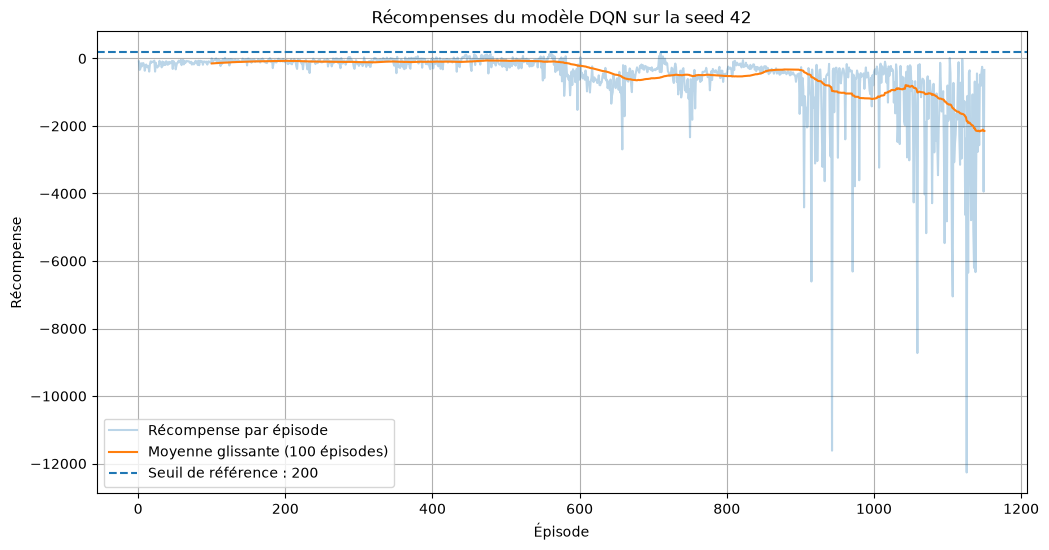

In [10]:
for k in seeds:

    fichier_final = Path(f"results_DQN_{k}.csv")

    with fichier_final.open("r", newline="", encoding="utf-8") as file:

        reader = csv.DictReader(file)

        episodes = []
        rewards = []

        for row in reader:
            episodes.append(int(row["episode"]))
            rewards.append(float(row["reward"]))

    moving_average = np.convolve(rewards, np.ones(100) / 100, mode="valid")

    plt.figure(figsize=(12, 6))

    plt.plot(episodes,rewards, alpha=0.3, label="Récompense par épisode")
    plt.plot(episodes[100 - 1:], moving_average, label="Moyenne glissante (100 épisodes)")
    plt.axhline(y=200,linestyle="--",label="Seuil de référence : 200")

    plt.xlabel("Épisode")
    plt.ylabel("Récompense")
    plt.title(f"Récompenses du modèle DQN sur la seed {k}")
    plt.legend()

    plt.grid(True)
    plt.show()

## Graphiques "Fin du modèle durant les épisodes"

Pour également voir l'amélioration du modèle au cours des entrainements, on affiche la fin de chaque épisode pour voir de quelle manière celui-ci c'est terminé (si c'est par un crash, un truncated ou qu'il s'est posé par exemple)

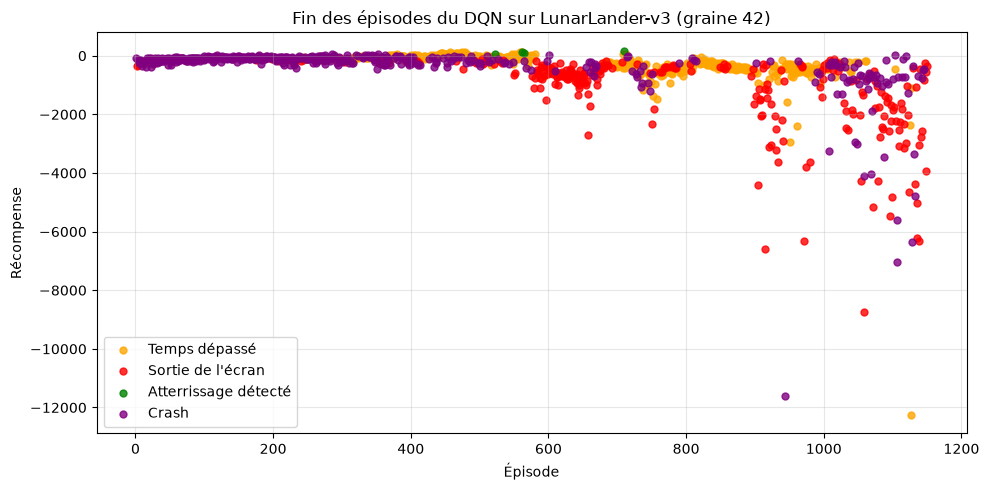

In [11]:
# Catégories de fin d'épisode
colors = {
    "truncated": "orange",
    "out_of_viewport": "red",
    "at_rest": "green",
    "crash": "purple"
}

labels = {
    "truncated": "Temps dépassé",
    "out_of_viewport": "Sortie de l'écran",
    "at_rest": "Atterrissage détecté",
    "crash": "Crash"
}

for k in seeds:

    # Lire les résultats du CSV correspondant à la graine
    fichier_final = Path(f"results_DQN_{k}.csv")

    with fichier_final.open("r", newline="", encoding="utf-8") as file:

        reader = csv.DictReader(file)
        results = []

        for row in reader:
            results.append({
                "episode": int(row["episode"]),
                "reward": float(row["reward"]),
                "end_reason": row["end_reason"]
            })

    plt.figure(figsize=(10, 5))

    # Ajouter un point pour chaque épisode, selon sa fin
    for reason, color in colors.items():

        x = [
            result["episode"]
            for result in results
            if result["end_reason"] == reason
        ]

        y = [
            result["reward"]
            for result in results
            if result["end_reason"] == reason
        ]

        if x:
            plt.scatter(
                x,
                y,
                color=color,
                label=labels[reason],
                s=25,
                alpha=0.8
            )

    plt.xlabel("Épisode")
    plt.ylabel("Récompense")
    plt.title(f"Fin des épisodes du DQN sur LunarLander-v3 (graine {k})")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

# Évaluation finale des différentes seeds.

Ici, on viens évaluer les modèles DQN entrainer avec les différentes seeds. On met l'Epsilon à 0 pour qu'il n'y est plus du tout d'exploration et que l'évaluation ne se fasse que sur les expériences passés du modèles durant son expérience.

In [15]:
print("\n------- BILAN -------")

for j in seeds:# Nombre d'épisodes à exécuter (Les épisodes sont les "simulations" qui se termine lorsque le module c'est posé, c'est craché ou à mis trop de temps)
    N_EPISODES = 100

    # On va venir définir nos variables pour Epsilon afin que celui-ci commence à 1 pour qu'il ne tente pas d'utiliser des expériences qui n'existent pas encore.
    epsilon = 0.0
    # On défini une seed et on la fixe à tous les éléments qui utilise de l'aléatoire. Cela va permettre de s'approcher aux mieux d'une reproductibilté parfaite

    SEED = 42
    random.seed(SEED) 
    np.random.seed(SEED) 
    torch.manual_seed(SEED)

    # Création de l'environnement sans affichage graphique
    env = gym.make("LunarLander-v3")

    # Initialisation de la graine aléatoire
    env.action_space.seed(42)

    # On va créer un CSV afin de sauvergarder les résultats
    fichier_final = Path(f"results_DQN_evaluation_{j}.csv")

    # Liste qui contiendra les résultats des épisodes
    results = []
    raison_de_fin_dqn = {"truncated" : 0, "out_of_viewport" : 0, "at_rest" : 0, "crash" : 0}

    # Création du modèle DQN
    model = DQN()
    model.load_state_dict(torch.load(f"lunarlander_dqn_seed_{j}.pth", map_location="cpu"))
    model.eval()

    # Exécution des épisodes
    for episode in range(1, N_EPISODES + 1):

        # Démarrage d'un nouvel épisodeµ
        etat_actuel, info = env.reset(seed=SEED + episode - 1)

        # On initialise les récompenses et les "pas" nombre de frame pris par le module jusqu'à terminer l'épisode.
        recompense_totale = 0.0
        steps = 0

        # On initialise terminated et truncated à false (terminated = Posé / Crash / sorti de l'écran | truncated = trop de temps)  
        terminated = False
        truncated = False

        # L'agent joue jusqu'à la fin de l'épisode
        while not (terminated or truncated):

            # Initialisation du choix de l'action
            action = select_action(etat_actuel, model, epsilon)

            # Execution de l'action
            next_state, reward, terminated, truncated, info = env.step(action)

            experience = etat_actuel, action, reward, next_state, terminated, truncated

            # On met à jour les statistiques
            recompense_totale += reward
            steps += 1

            # Et enfin on passe à l'état suivant
            etat_actuel = next_state

        reason = end_reason(truncated, next_state, reward)
        
        # On enregistre les résultats de l'épisode
        result = {
            "episode": episode,
            "reward": round(recompense_totale, 2),
            "steps": steps,
            "terminated": terminated,
            "truncated": truncated,
            "end_reason": reason
        }

        # On les ajoute dans la liste results
        results.append(result)

        raison_de_fin_dqn[end_reason(truncated, next_state, reward)] += 1

    # Fermeture de l'environnement
    env.close()

    # Ecriture des résultat dans le CSV afin de pouvoir les réutiliser pour des graphiques et les tests finaux
    with fichier_final.open("w", newline="", encoding="utf-8") as file:

        # Création des 5 colonnes qui sont les différentes paramètres du modèle
        colonnes = ["episode", "reward", "steps", "terminated", "truncated", "end_reason"]

        writer = csv.DictWriter(file, fieldnames=colonnes)

        # writeheader permet d'écrire les noms des colonnes enregistrer dans le paramètres fieldnames
        writer.writeheader()
        writer.writerows(results)

    # Calcul des statistiques globales
    mean_reward = sum(r["reward"] for r in results[-100:]) / len(results[-100:])

    print(f"Évaluation de la seed : {j}")
    print(f"Récompense moyenne : {mean_reward:.2f} \n")


------- BILAN -------
Évaluation de la seed : 42
Récompense moyenne : -930.11 

